# 02. Stride 전달과 합성곱 시각화
`02_응용/02_stride.py`를 바탕으로 반복문의 stride 값을 `Conv2d`에 전달하고, 필터 이동 간격·출력 크기·연산량의 차이를 확인합니다.

## 0. 작업 전 준비사항
PyTorch, pandas, matplotlib이 설치된 Python 커널에서 **Run All(모두 실행)**로 실행합니다. 작은 난수 텐서를 사용하므로 CPU로 충분하며 별도 데이터 다운로드가 필요하지 않습니다.

기존 Python 파일을 수정하지 않고 노트북 안에서 실험합니다. 그림과 CSV는 `20261102/02_응용/docs/outputs`에 저장합니다.

In [1]:
%matplotlib inline
from pathlib import Path
import torch
from torch import nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

torch.set_num_threads(1)
cwd = Path.cwd().resolve()
day_root = next((candidate for parent in (cwd, *cwd.parents)
                 for candidate in (parent / "20261102", parent)
                 if (candidate / "02_응용" / "02_stride.py").is_file()), None)
if day_root is None:
    raise FileNotFoundError("이 저장소 안에서 노트북을 실행하세요.")
out = day_root / "02_응용" / "docs" / "outputs"
out.mkdir(parents=True, exist_ok=True)
print("PyTorch:", torch.__version__)
print("실습 장치: CPU")

PyTorch: 2.14.0+cu130
실습 장치: CPU


## 1. 현재 반복의 stride를 전달하는 방법
```python
for stride in [1, 2]:
    conv = nn.Conv2d(3, 8, 3, stride=stride, padding=1)
```

`stride=stride`의 **왼쪽**은 `Conv2d`가 받는 인자 이름이고, **오른쪽**은 반복문의 변수입니다. 첫 반복은 1, 다음 반복은 2를 전달합니다. `stride=1`로 고정하면 두 반복 모두 같은 이동 간격을 사용하게 됩니다.

| 인자 | 이번 값 | 의미 |
| --- | --- | --- |
| `in_channels` | 3 | 입력 RGB 채널 수 |
| `out_channels` | 8 | 출력 특징 맵 수 |
| `kernel_size` | 3 | 필터의 공간 크기 3×3 |
| `stride` | 1 또는 2 | 필터가 가로·세로로 이동하는 간격 |
| `padding` | 1 | 입력 가장자리에 0을 한 칸씩 추가 |

정수 stride는 높이와 너비 양쪽에 적용됩니다. `(2, 1)`처럼 튜플을 쓰면 세로와 가로 간격을 다르게 줄 수도 있습니다.

## 2. 그림으로 보는 필터 이동과 출력 크기
이동을 쉽게 보기 위해 먼저 **5×5 입력, 3×3 필터, padding=0** 예시를 봅니다. 색칠한 영역은 같은 행에서 필터가 처음 두 번 놓이는 위치입니다. 입력값은 위치를 구분하기 위한 번호입니다.

stride=1은 한 칸씩 이동하여 3×3 출력을 만들고, stride=2는 두 칸씩 이동하여 2×2 출력을 만듭니다. 아래 그림은 실제 실습의 32×32 입력·padding=1과 구분되는 설명용 예시입니다.

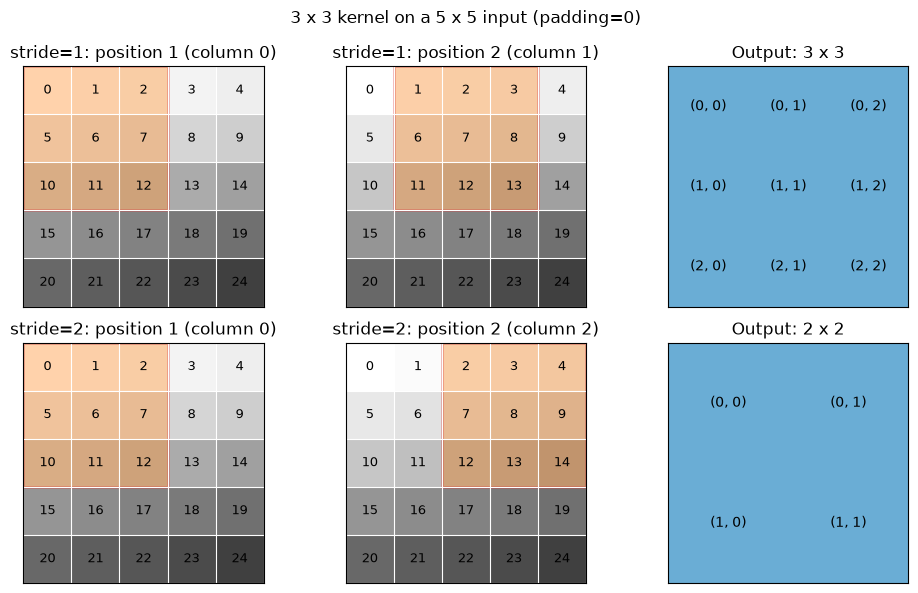

In [2]:
grid = np.arange(25).reshape(5, 5)
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for row, stride in enumerate([1, 2]):
    for col, start in enumerate([0, stride]):
        ax = axes[row, col]
        ax.imshow(grid, cmap="Greys", vmin=0, vmax=30)
        for h in range(5):
            for w in range(5):
                ax.text(w, h, str(grid[h, w]), ha="center", va="center", fontsize=9)
        ax.add_patch(Rectangle((start - 0.5, -0.5), 3, 3,
                               facecolor="tab:orange", edgecolor="tab:red", alpha=0.35, linewidth=2))
        ax.set_title(f"stride={stride}: position {col + 1} (column {start})")
        ax.set_xticks(np.arange(-0.5, 5, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, 5, 1), minor=True)
        ax.grid(which="minor", color="white")
        ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)
    size = (5 - 3) // stride + 1
    ax = axes[row, 2]
    ax.imshow(np.ones((size, size)), cmap="Blues", vmin=0, vmax=2)
    for h in range(size):
        for w in range(size):
            ax.text(w, h, f"({h}, {w})", ha="center", va="center")
    ax.set_title(f"Output: {size} x {size}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("3 x 3 kernel on a 5 x 5 input (padding=0)")
fig.tight_layout()
fig.savefig(out / "stride_movement.png", dpi=140)
plt.show()
plt.close(fig)

## 3. 실제 실습: 출력 형태·파라미터·MACs 비교
입력 `x`는 NCHW `(4, 3, 32, 32)`입니다. 네 장의 이미지에 3×3 필터를 적용해 채널 8개를 만듭니다. 동일한 입력을 사용하고, 각 층을 만들기 직전에 같은 seed를 주어 가중치와 편향을 동일하게 맞춥니다.

출력 높이는 다음 식으로 구합니다. 너비도 같은 방식이며, 이번 dilation은 기본값 1입니다.

$$H_{out}=\left\lfloor\frac{H+2P-D(K-1)-1}{S}\right\rfloor+1$$

- stride=1: `floor((32 + 2 - 3) / 1) + 1 = 32`
- stride=2: `floor((32 + 2 - 3) / 2) + 1 = 16`

파라미터 수는 `8 × (3 × 3 × 3) + 8 = 224`입니다. 마지막 8은 편향입니다. stride는 학습 파라미터의 개수를 바꾸지 않습니다.

MACs는 곱셈 후 누적 횟수입니다. 출력 원소마다 `입력 채널 3 × 필터 높이 3 × 필터 너비 3 = 27`회를 계산합니다. 아래 MACs는 **네 장의 배치 전체**를 기준으로 하며 편향 덧셈은 제외합니다. 실제 실행 시간과 동일한 지표는 아닙니다.

In [3]:
torch.manual_seed(42)
x = torch.rand(4, 3, 32, 32)
rows = []
outputs = {}
layers = {}
for stride in [1, 2]:
    torch.manual_seed(42)
    conv = nn.Conv2d(3, 8, 3, stride=stride, padding=1)
    with torch.no_grad():
        y = conv(x)
    layers[stride] = conv
    outputs[stride] = y
    params = sum(p.numel() for p in conv.parameters())
    macs = y.numel() * (3 * 3 * 3)
    rows.append(dict(stride=stride, shape=str(tuple(y.shape)), params=params, macs=macs))

results = pd.DataFrame(rows)
print(results.to_string(index=False))
results.to_csv(out / "stride_comparison.csv", index=False)
assert torch.equal(layers[1].weight, layers[2].weight)
assert torch.equal(layers[1].bias, layers[2].bias)
assert outputs[1].shape == (4, 8, 32, 32)
assert outputs[2].shape == (4, 8, 16, 16)
# 같은 필터와 padding이므로 stride=2는 stride=1 출력의 두 칸 간격 위치에 대응합니다.
assert torch.allclose(outputs[1][:, :, ::2, ::2], outputs[2], atol=1e-6)
print("동일 가중치·출력 크기·샘플링 위치 확인 완료")

 stride          shape  params   macs
      1 (4, 8, 32, 32)     224 884736
      2 (4, 8, 16, 16)     224 221184
동일 가중치·출력 크기·샘플링 위치 확인 완료


### 동일한 출력 채널을 나란히 비교하기
첫 번째 이미지의 첫 번째 출력 채널을 같은 색 범위로 표시합니다. stride=2는 출력 위치를 더 성기게 계산합니다. 같은 크기의 그림으로 표시되어도 실제 격자 크기는 각각 32×32와 16×16입니다. 특징 맵의 색은 합성곱 출력값이며 RGB 색상이 아닙니다.

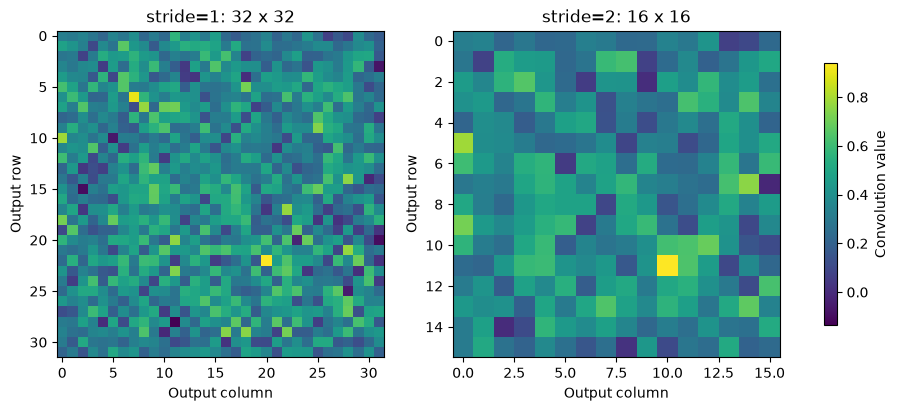

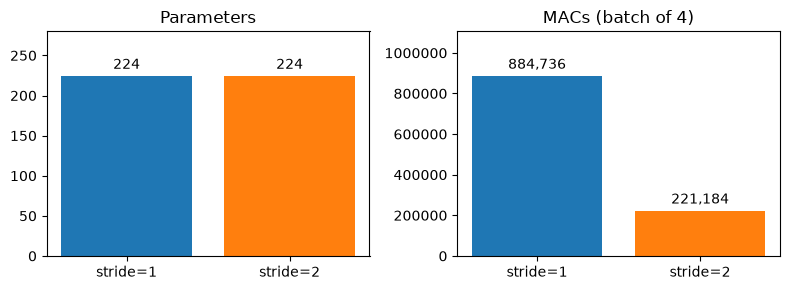

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
vmin = min(y[0, 0].min().item() for y in outputs.values())
vmax = max(y[0, 0].max().item() for y in outputs.values())
for ax, stride in zip(axes, [1, 2]):
    feature = outputs[stride][0, 0].numpy()
    im = ax.imshow(feature, cmap="viridis", vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_title(f"stride={stride}: {feature.shape[0]} x {feature.shape[1]}")
    ax.set_xlabel("Output column")
    ax.set_ylabel("Output row")
fig.colorbar(im, ax=axes, label="Convolution value", shrink=0.8)
fig.savefig(out / "stride_feature_maps.png", dpi=140)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, key, title in zip(axes, ["params", "macs"], ["Parameters", "MACs (batch of 4)"]):
    bars = ax.bar(["stride=1", "stride=2"], results[key], color=["tab:blue", "tab:orange"])
    ax.bar_label(bars, labels=[f"{value:,}" for value in results[key]], padding=3)
    ax.set_title(title)
    ax.set_ylim(0, results[key].max() * 1.25)
    ax.ticklabel_format(axis="y", style="plain")
fig.tight_layout()
fig.savefig(out / "stride_cost_comparison.png", dpi=140)
plt.show()
plt.close(fig)

## 4. 결과 해석 및 추가 실험
| stride | 출력 NCHW | 파라미터 수 | 배치 전체 MACs |
| --- | --- | --- | --- |
| 1 | `(4, 8, 32, 32)` | 224 | 884,736 |
| 2 | `(4, 8, 16, 16)` | 224 | 221,184 |

이번 조건에서 stride=2는 높이·너비가 각각 절반이므로 출력 원소 수와 MACs가 1/4로 줄어듭니다. 필터 개수와 크기는 같아서 파라미터 수는 유지됩니다. 더 큰 stride는 공간 해상도를 낮추므로 작은 패턴이나 세부 위치 정보를 놓칠 수 있습니다. 항상 정확도가 좋아지거나 실제 실행 시간이 정확히 1/4이 되는 것은 아닙니다.

### 직접 확인해 볼 내용
- `stride` 후보에 3을 추가하고 출력이 `(4, 8, 11, 11)`인지 식으로 먼저 계산합니다. 위 검증 셀은 stride=1과 2를 비교하므로 그대로 유지할 수 있습니다.
- `padding=0`으로 바꾸면 출력 크기가 어떻게 바뀌는지 계산하고 확인합니다. 이 경우 기본 설정용 shape 검증도 새 예상값으로 바꿉니다.
- 입력 채널과 필터 크기를 유지한 채 `out_channels=16`으로 바꿔 파라미터와 MACs의 변화를 확인합니다.

### 자주 하는 실수 점검
- `stride=1`로 고정하여 반복 변수의 값이 전달되지 않고 있지 않은가?
- 정수 stride가 높이와 너비 양쪽에 적용된다는 점을 고려했는가?
- 출력 크기 계산에서 padding과 내림 연산을 빠뜨리지 않았는가?
- 파라미터 수, 연산량, 실제 실행 시간을 구분했는가?
- 특징 맵의 색을 원본 이미지의 RGB 색과 혼동하지 않았는가?